In [1]:
# ==============================================================================
# BÀI LAB 02: GIẢI PHẪU AE VS. VAE — LẬP BẢN ĐỒ KHÔNG GIAN ẨN & KHOẢNG TRỐNG CHẾT
# Môn: Generative Learning / Representation Learning
# ==============================================================================

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

# ------------------------------------------------------------------------------
# 0. KHỞI TẠO VÀ CHUẨN BỊ DỮ LIỆU
# ------------------------------------------------------------------------------
torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[+] Thiết bị thực thi: {device}")

# Chuẩn hóa ảnh về khoảng [0, 1]
transform = transforms.Compose([
    transforms.ToTensor()
])

train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)


# ==============================================================================
# 1. ĐỊNH NGHĨA KIẾN TRÚC AUTOENCODER (AE) VÀ VARIATIONAL AUTOENCODER (VAE)
# Không gian tiềm ẩn được cố định z in R^2 để trực quan hóa trực tiếp trên Oxy
# ==============================================================================

class Autoencoder(nn.Module):
    """
    Autoencoder truyền thống (Deterministic Mapping):
    Encoder ánh xạ ảnh x thành một điểm tọa độ cố định z trong R^2.
    """
    def __init__(self, latent_dim=2):
        super().__init__()
        # Encoder: 784 -> 512 -> 256 -> 2
        self.encoder = nn.Sequential(
            nn.Linear(784, 512),
            nn.ReLU(inplace=True),
            nn.Linear(512, 256),
            nn.ReLU(inplace=True),
            nn.Linear(256, latent_dim)
        )
        # Decoder: 2 -> 256 -> 512 -> 784
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(inplace=True),
            nn.Linear(256, 512),
            nn.ReLU(inplace=True),
            nn.Linear(512, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        x_flat = x.view(x.size(0), -1)
        z = self.encoder(x_flat)
        x_recon = self.decoder(z)
        return x_recon.view(x.size(0), 1, 28, 28), z


class VariationalAutoencoder(nn.Module):
    """
    Variational Autoencoder (Probabilistic Mapping):
    Encoder dự đoán tâm (mu) và log-phương sai (logvar) của đám mây xác suất q(z|x).
    Sử dụng Reparameterization Trick để truyền ngược gradient.
    """
    def __init__(self, latent_dim=2):
        super().__init__()
        self.latent_dim = latent_dim
        
        # Backbone trích xuất đặc trưng chung
        self.encoder_backbone = nn.Sequential(
            nn.Linear(784, 512),
            nn.ReLU(inplace=True),
            nn.Linear(512, 256),
            nn.ReLU(inplace=True)
        )
        
        # Hai nhánh chiếu ra tham số phân phối Gaussian
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)
        
        # Decoder: 2 -> 256 -> 512 -> 784
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(inplace=True),
            nn.Linear(256, 512),
            nn.ReLU(inplace=True),
            nn.Linear(512, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder_backbone(x.view(x.size(0), -1))
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        """
        Reparameterization Trick: z = mu + sigma * epsilon, với epsilon ~ N(0, I).
        Tách tính ngẫu nhiên ra khỏi đồ thị vi phân để backpropagation truyền mượt mà.
        """
        if self.training:
            std = torch.exp(0.5 * logvar)
            eps = torch.randn_like(std)
            return mu + eps * std
        return mu  # Khi inference/eval, sử dụng vector trung bình mu

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        recon_x = self.decode(z)
        return recon_x, mu, logvar, z


# ------------------------------------------------------------------------------
# HÀM MẤT MÁT VAE: CẬN DƯỚI BIẾN PHÂN (ELBO)
# ------------------------------------------------------------------------------
def vae_loss_function(recon_x, x, mu, logvar):
    """
    ELBO = Reconstruction Loss (Lực kéo) + KL Divergence (Lực nén)
    - Reconstruction Loss: Đo lường độ nét của ảnh tái tạo (dùng BCE).
    - KL Divergence: Ép phân phối hậu nghiệm q(z|x) khớp với phân phối chuẩn tắc N(0, I).
      D_KL = -0.5 * sum(1 + log(sigma^2) - mu^2 - sigma^2)
    """
    recon_loss = F.binary_cross_entropy(recon_x.view(-1, 784), x.view(-1, 784), reduction='sum')
    kl_div = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return recon_loss + kl_div


# ==============================================================================
# 2. QUÁ TRÌNH HUẤN LUYỆN HAI MÔ HÌNH (TRAINING PIPELINE)
# ==============================================================================
EPOCHS = 10
ae_model = Autoencoder(latent_dim=2).to(device)
vae_model = VariationalAutoencoder(latent_dim=2).to(device)

ae_optimizer = torch.optim.Adam(ae_model.parameters(), lr=1e-3)
vae_optimizer = torch.optim.Adam(vae_model.parameters(), lr=1e-3)
ae_criterion = nn.MSELoss(reduction='sum')

print("\n" + "="*60)
print("TIẾN HÀNH HUẤN LUYỆN AUTOENCODER (AE) VÀ VARIATIONAL AUTOENCODER (VAE)")
print("="*60)

for epoch in range(1, EPOCHS + 1):
    ae_model.train()
    vae_model.train()
    total_ae_loss = 0.0
    total_vae_loss = 0.0

    for images, _ in train_loader:
        images = images.to(device)
        batch_size = images.size(0)

        # 1. Tối ưu Autoencoder (MSE Loss)
        ae_optimizer.zero_grad()
        ae_recon, _ = ae_model(images)
        loss_ae = ae_criterion(ae_recon, images)
        loss_ae.backward()
        ae_optimizer.step()
        total_ae_loss += loss_ae.item()

        # 2. Tối ưu VAE (ELBO: BCE + KL)
        vae_optimizer.zero_grad()
        vae_recon, mu, logvar, _ = vae_model(images)
        loss_vae = vae_loss_function(vae_recon, images, mu, logvar)
        loss_vae.backward()
        vae_optimizer.step()
        total_vae_loss += loss_vae.item()

    num_samples = len(train_loader.dataset)
    print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] | "
          f"AE Loss (MSE/sample): {total_ae_loss / num_samples:.2f} | "
          f"VAE Loss (ELBO/sample): {total_vae_loss / num_samples:.2f}")



[+] Thiết bị thực thi: cuda


  0%|          | 0.00/9.91M [00:00<?, ?B/s]

  0%|          | 32.8k/9.91M [00:34<2:53:30, 949B/s]

  1%|          | 65.5k/9.91M [00:43<1:37:34, 1.68kB/s]

  1%|          | 98.3k/9.91M [00:51<1:12:12, 2.27kB/s]

...

Epoch [06/10] | AE Loss (MSE/sample): 30.31 | VAE Loss (ELBO/sample): 146.93


Epoch [07/10] | AE Loss (MSE/sample): 29.86 | VAE Loss (ELBO/sample): 145.98


Epoch [08/10] | AE Loss (MSE/sample): 29.62 | VAE Loss (ELBO/sample): 145.10


Epoch [09/10] | AE Loss (MSE/sample): 29.25 | VAE Loss (ELBO/sample): 144.21


Epoch [10/10] | AE Loss (MSE/sample): 29.07 | VAE Loss (ELBO/sample): 143.27



TASK 1: Vẽ bản đồ không gian ẩn 2D trên 2.000 mẫu test


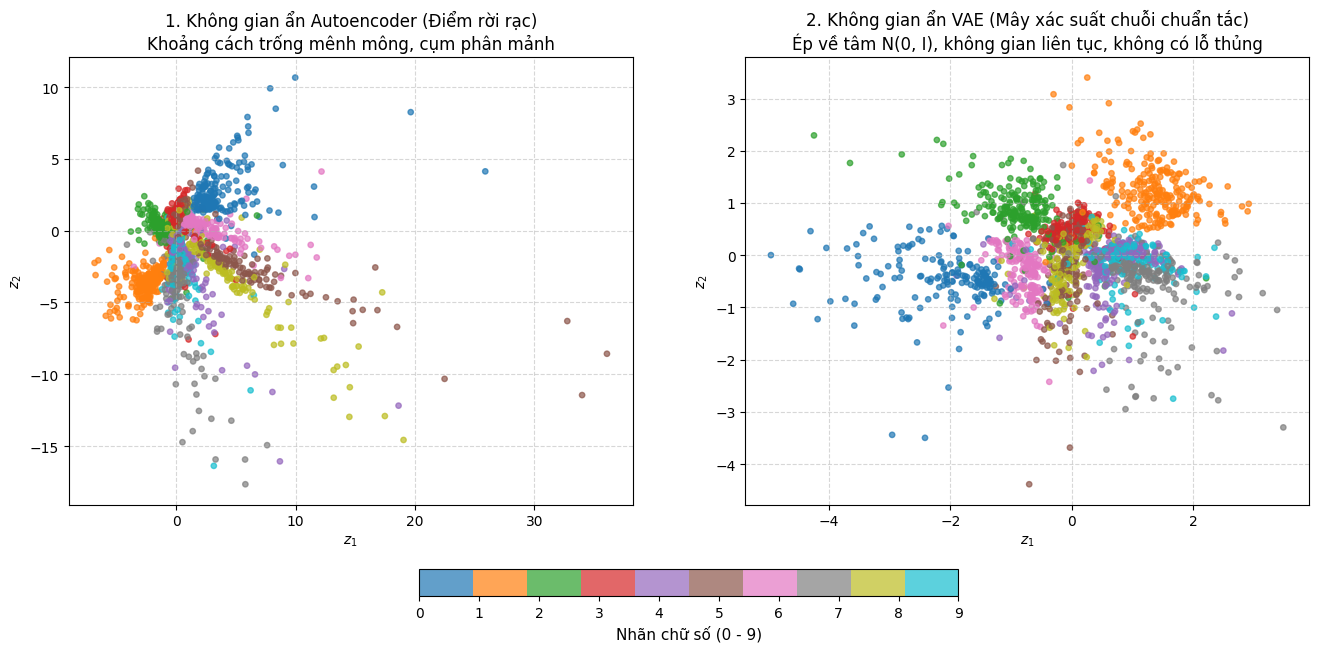

In [2]:
# ==============================================================================
# TASK 1: BẢN ĐỒ KHÔNG GIAN ẨN (LATENT SPACE SCATTER PLOT)
# ==============================================================================
print("\n" + "="*60)
print("TASK 1: Vẽ bản đồ không gian ẩn 2D trên 2.000 mẫu test")
print("="*60)

ae_model.eval()
vae_model.eval()

all_z_ae = []
all_z_vae = []
all_labels = []
total_test_points = 2000

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        
        # AE: lấy trực tiếp vector tiềm ẩn z
        _, z_ae = ae_model(images)
        # VAE: lấy vector trung bình mu (tâm của đám mây xác suất)
        mu, _ = vae_model.encode(images)
        
        all_z_ae.append(z_ae.cpu())
        all_z_vae.append(mu.cpu())
        all_labels.append(labels)
        
        if sum(x.size(0) for x in all_labels) >= total_test_points:
            break

all_z_ae = torch.cat(all_z_ae, dim=0)[:total_test_points].numpy()
all_z_vae = torch.cat(all_z_vae, dim=0)[:total_test_points].numpy()
all_labels = torch.cat(all_labels, dim=0)[:total_test_points].numpy()

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Biểu đồ AE
scatter_ae = axes[0].scatter(all_z_ae[:, 0], all_z_ae[:, 1], c=all_labels, cmap='tab10', alpha=0.7, s=15)
axes[0].set_title("1. Không gian ẩn Autoencoder (Điểm rời rạc)\nKhoảng cách trống mênh mông, cụm phân mảnh", fontsize=12)
axes[0].set_xlabel("$z_1$")
axes[0].set_ylabel("$z_2$")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Biểu đồ VAE
scatter_vae = axes[1].scatter(all_z_vae[:, 0], all_z_vae[:, 1], c=all_labels, cmap='tab10', alpha=0.7, s=15)
axes[1].set_title("2. Không gian ẩn VAE (Mây xác suất chuỗi chuẩn tắc)\nÉp về tâm N(0, I), không gian liên tục, không có lỗ thủng", fontsize=12)
axes[1].set_xlabel("$z_1$")
axes[1].set_ylabel("$z_2$")
axes[1].grid(True, linestyle="--", alpha=0.5)

cbar = fig.colorbar(scatter_vae, ax=axes, orientation='horizontal', fraction=0.05, pad=0.12)
cbar.set_ticks(range(10))
cbar.set_label("Nhãn chữ số (0 - 9)", fontsize=11)
plt.show()



TASK 2: Lấy mẫu 64 điểm ngẫu nhiên z ~ N(0, I) đưa qua Decoder của AE và VAE


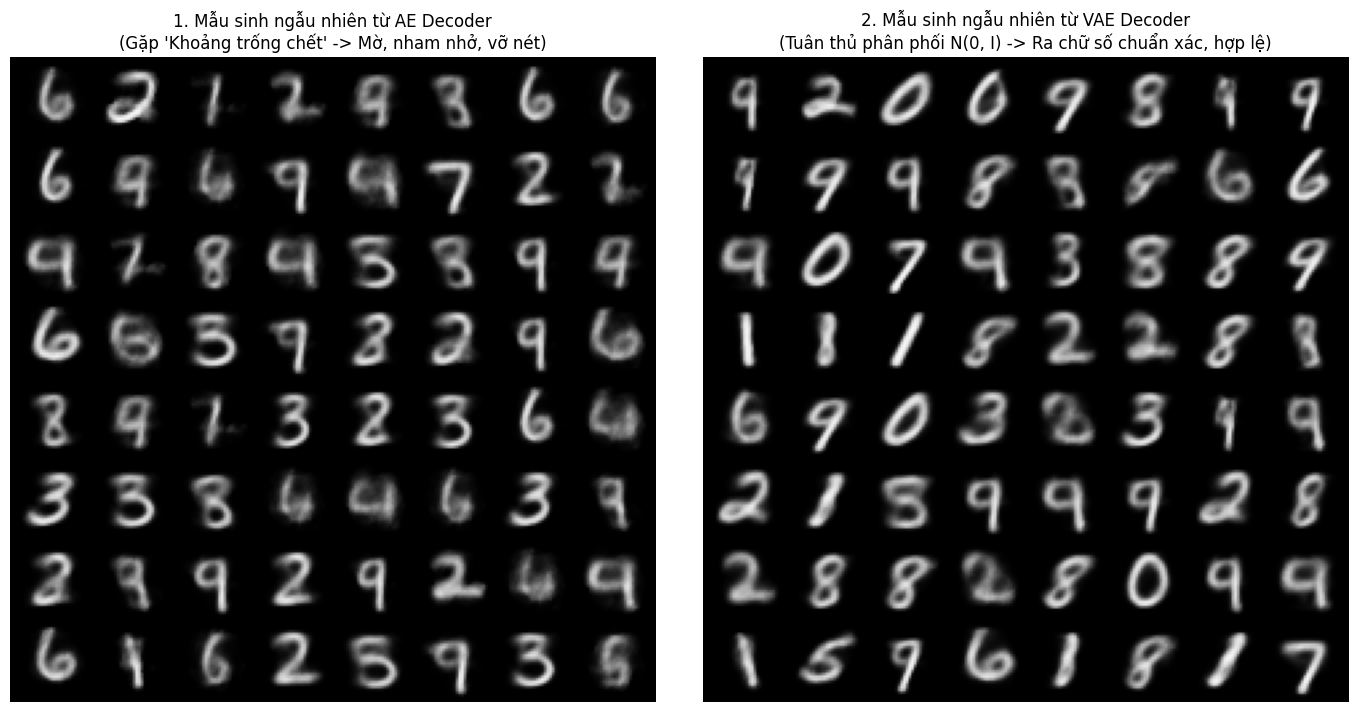

In [3]:
# ==============================================================================
# TASK 2: PHÉP THỬ LẤY MẪU NGẪU NHIÊN (PRIOR SAMPLING: z ~ N(0, I))
# ==============================================================================
print("\n" + "="*60)
print("TASK 2: Lấy mẫu 64 điểm ngẫu nhiên z ~ N(0, I) đưa qua Decoder của AE và VAE")
print("="*60)

num_prior_samples = 64
# Bốc ngẫu nhiên 64 vector tiềm ẩn từ phân phối chuẩn tắc
z_random = torch.randn(num_prior_samples, 2).to(device)

with torch.no_grad():
    ae_generated = ae_model.decoder(z_random).view(-1, 1, 28, 28).cpu()
    vae_generated = vae_model.decode(z_random).cpu()

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

grid_ae = make_grid(ae_generated, nrow=8, padding=2)
axes[0].imshow(grid_ae.permute(1, 2, 0).numpy(), cmap='gray')
axes[0].set_title("1. Mẫu sinh ngẫu nhiên từ AE Decoder\n(Gặp 'Khoảng trống chết' -> Mờ, nham nhở, vỡ nét)", fontsize=12)
axes[0].axis("off")

grid_vae = make_grid(vae_generated, nrow=8, padding=2)
axes[1].imshow(grid_vae.permute(1, 2, 0).numpy(), cmap='gray')
axes[1].set_title("2. Mẫu sinh ngẫu nhiên từ VAE Decoder\n(Tuân thủ phân phối N(0, I) -> Ra chữ số chuẩn xác, hợp lệ)", fontsize=12)
axes[1].axis("off")

plt.tight_layout()
plt.show()



TASK 3: Quét tọa độ 2D [-3, 3] x [-3, 3] trên lưới 20x20 đưa qua Decoder


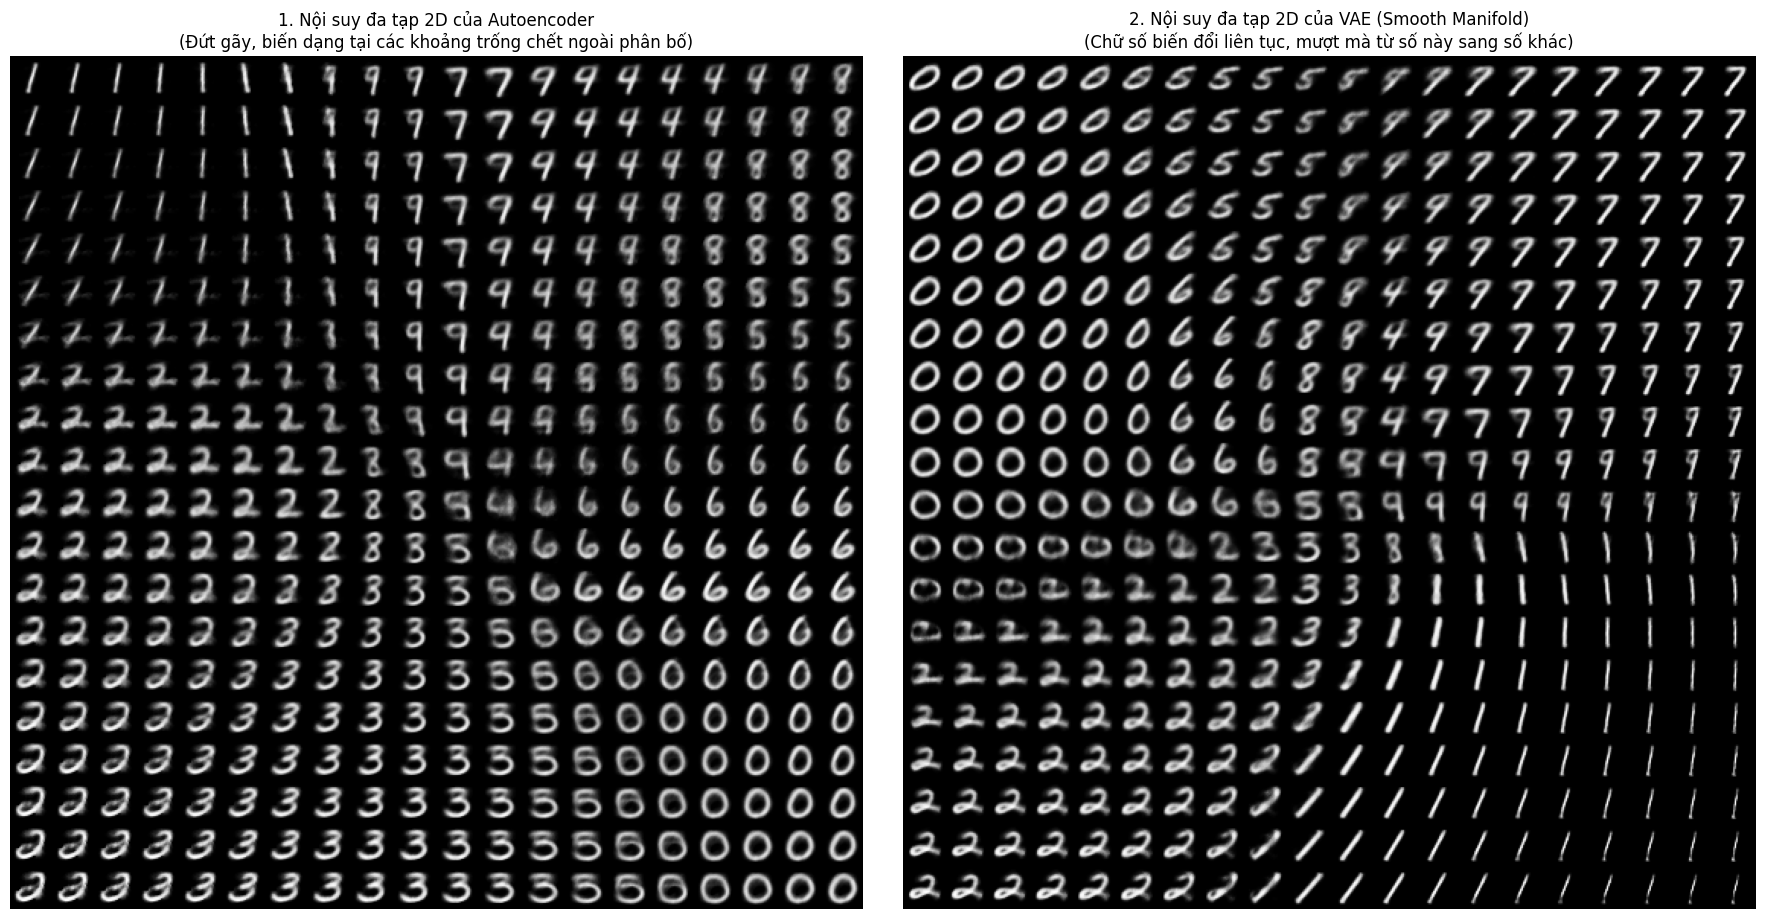

In [4]:
# ==============================================================================
# TASK 3: QUÉT LƯỚI KHÔNG GIAN TIỀM ẨN (2D LATENT MANIFOLD GRID GENERATION)
# ==============================================================================
print("\n" + "="*60)
print("TASK 3: Quét tọa độ 2D [-3, 3] x [-3, 3] trên lưới 20x20 đưa qua Decoder")
print("="*60)

grid_size = 20
grid_x = np.linspace(-3.0, 3.0, grid_size)
grid_y = np.linspace(-3.0, 3.0, grid_size)

canvas_ae = np.zeros((28 * grid_size, 28 * grid_size))
canvas_vae = np.zeros((28 * grid_size, 28 * grid_size))

with torch.no_grad():
    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):
            z_point = torch.tensor([[xi, yi]], dtype=torch.float32).to(device)
            
            # Giải mã điểm tọa độ qua AE và VAE
            digit_ae = ae_model.decoder(z_point).cpu().view(28, 28).numpy()
            digit_vae = vae_model.decode(z_point).cpu().view(28, 28).numpy()
            
            canvas_ae[i * 28:(i + 1) * 28, j * 28:(j + 1) * 28] = digit_ae
            canvas_vae[i * 28:(i + 1) * 28, j * 28:(j + 1) * 28] = digit_vae

fig, axes = plt.subplots(1, 2, figsize=(18, 9))

axes[0].imshow(canvas_ae, cmap='gray')
axes[0].set_title("1. Nội suy đa tạp 2D của Autoencoder\n(Đứt gãy, biến dạng tại các khoảng trống chết ngoài phân bố)", fontsize=12)
axes[0].axis("off")

axes[1].imshow(canvas_vae, cmap='gray')
axes[1].set_title("2. Nội suy đa tạp 2D của VAE (Smooth Manifold)\n(Chữ số biến đổi liên tục, mượt mà từ số này sang số khác)", fontsize=12)
axes[1].axis("off")

plt.tight_layout()
plt.show()